# Triagem de pull requests com árvore de decisão e regras

Brayan Aragão Pletsch | RGM 38473585 | Engenharia de Software - N1

Inteligência Artificial e LFA | Profª Kadidja Valéria | Aula 13 (09/11/2026) | Sistema especialista com aprendizado supervisionado

Adaptei o notebook do orientador de estudos para um problema da minha área: decidir quanto cuidado um pull request (PR) precisa na revisão de código. Uma árvore de decisão olha o tamanho do PR e se ele tem teste, e prevê o risco de dar problema depois do merge. Essa previsão vira um fato para o sistema especialista, que junta com uma informação dada pelo time (se o PR mexe em uma parte crítica do sistema) e recomenda como revisar.

Arquivos desta entrega, na pasta `AprendizadoDeMaquina/` do meu repositório:

- `BrayanPletsch_Atividade_AprendizadoSupervisionado.ipynb`: este notebook;
- `dataset_pull_requests.csv`: o dataset, com 200 PRs simulados;
- `gerar_dataset.py`: o script que gerou o dataset (semente fixa, sempre gera o mesmo CSV).

Para rodar no Colab: Ambiente de execução > Executar tudo. Se o CSV não estiver na mesma pasta, o notebook baixa o arquivo do GitHub.

## 1. Estudo inicial

Leitura: o guia de aprendizado de máquina da IBM (Stryker et al., 2025) e a página sobre aprendizado supervisionado (Belcic; Stryker, 2025).

### O que é aprendizado de máquina?

Pelo guia da IBM, é a parte da IA que trata de algoritmos que aprendem padrões a partir de dados de treinamento e depois usam esses padrões para fazer inferências sobre dados novos, sem que alguém escreva a instrução para cada caso. Comparando com o que fizemos até aqui na disciplina: no AFD e na Máquina de Turing eu escrevi cada transição à mão. Aqui eu entrego exemplos e o algoritmo monta as condições.

### O que caracteriza o aprendizado supervisionado?

O treino usa dados rotulados, ou seja, cada exemplo já vem com a resposta certa. A IBM chama esses rótulos de "verdade fundamental", e é com eles que o modelo aprende a relação entre entrada e saída para depois prever a saída de casos novos. A mesma página lembra que rotular costuma ser manual e demorado, e que alguém ainda precisa validar o que o modelo devolve.

### O que são atributos e rótulos?

Atributos são as entradas que descrevem cada exemplo. Neste notebook são três: linhas alteradas, arquivos alterados e se o PR inclui teste. O rótulo é a resposta conhecida que o modelo tem que aprender a prever, aqui o `risco` (`alto` ou `baixo`). O guia da IBM chama de engenharia de funcionalidades o trabalho de escolher e transformar essas entradas a partir dos dados brutos. No meu caso, por exemplo, "o PR tem teste?" virou uma coluna com 0 ou 1.

### Como classificação difere de regressão?

Classificação prevê uma categoria dentro de um conjunto fixo. A IBM dá como exemplo identificar se um veículo é carro, moto, caminhão ou bicicleta, e separar spam. Regressão prevê um valor contínuo, como uma projeção de receita de vendas. O meu problema é de classificação, porque a saída é alto ou baixo. Se eu quisesse prever em quantos dias aparece um bug depois do merge, seria regressão.

### Por que separar treino e teste?

Para medir o modelo com exemplos que ele não viu. Avaliando com os próprios dados de treino, uma árvore funda consegue decorar os exemplos e parecer perfeita. A página da IBM diz que alta precisão no treinamento pode indicar overfitting e que, para evitar isso, o modelo tem que ser testado com dados diferentes dos de treinamento. Seguindo o aviso do notebook da professora, também não fiquei ajustando o modelo olhando o teste: escolhi a profundidade da árvore com validação cruzada só no treino (seção 5).

## 2. O problema

Quem usa: quem revisa PRs em um time de desenvolvimento.

Quando um PR chega, quem revisa decide quanto cuidado ele merece, mesmo que não pense nisso. Um PR de 15 linhas com teste e um de 900 linhas sem teste não deveriam passar pela mesma revisão. A ideia é uma triagem que sugere o tipo de revisão.

| | |
|:--|:--|
| Entradas do modelo | `linhas_alteradas`, `arquivos_alterados`, `inclui_testes` (0 ou 1) |
| Rótulo previsto | `risco`: `alto` se o PR precisou de revert ou hotfix em até 14 dias depois do merge, `baixo` se não precisou |
| Fato informado na consulta | `area_critica`: o PR mexe em autenticação, pagamento ou migração de banco? (`True`, `False`, ou `None` quando ninguém sabe ainda) |
| Saída do sistema | a recomendação de revisão, a regra que foi aplicada e o rastro da inferência |

Escolhi esses três atributos porque todos existem antes do merge e dá para pegar de qualquer PR pela API do GitHub. O rótulo só se conhece depois, olhando o histórico do PR, por isso faz sentido prever.

## 3. Preparar o ambiente

No Colab essas bibliotecas já vêm instaladas. Se aparecer `ModuleNotFoundError`, rodar `%pip install pandas scikit-learn matplotlib` em uma célula nova.

In [1]:
# pandas para os dados, matplotlib para os gráficos e scikit-learn para a árvore,
# a separação treino/teste, a validação cruzada e as métricas.
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import (accuracy_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay)

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 4. Dataset

Os dados são simulados. Não tenho o histórico de um projeto real com a informação de quais PRs deram problema, então escrevi o `gerar_dataset.py`, que sorteia 200 PRs com semente fixa. O tamanho segue uma distribuição log-normal (a maioria dos PRs é pequena e alguns são enormes), e o rótulo de cada PR é sorteado a partir de uma chance de dar problema que eu defini:

| Situação do PR | Soma na chance de risco alto |
|:--|--:|
| qualquer PR | 5% |
| mais de 300 linhas | +35% |
| mais de 800 linhas | +15% |
| mais de 12 arquivos | +10% |
| sem teste | +40% |

Os pesos são uma suposição minha, a partir da ideia comum de que PR grande e sem teste é o que mais volta com bug, e não foram medidos. Como o rótulo é sorteado, dois PRs com os mesmos números podem ter rótulos diferentes, o que imita o fato de que nem todo PR grande dá problema.

Colunas: `id_pr` (só identifica a linha, não entra no modelo), os três atributos e o rótulo `risco`.

In [2]:
# O CSV fica na mesma pasta do notebook no meu repositório. No Colab, se o arquivo
# não foi enviado junto, o notebook busca direto do GitHub.
CSV_LOCAL = Path("dataset_pull_requests.csv")
CSV_GITHUB = ("https://raw.githubusercontent.com/BrayanPletsch/"
              "InteligenciaArtifical_LinguagensFormais_Automatos/main/"
              "AprendizadoDeMaquina/dataset_pull_requests.csv")

dados = pd.read_csv(CSV_LOCAL if CSV_LOCAL.exists() else CSV_GITHUB)

print(f"{len(dados)} PRs, {dados.shape[1]} colunas\n")
print(dados.head(8).to_string(index=False))
print("\nQuantidade por classe:")
print(dados["risco"].value_counts())

200 PRs, 5 colunas

 id_pr  linhas_alteradas  arquivos_alterados  inclui_testes risco
PR-001               337                   9              0  alto
PR-002               315                  13              0  alto
PR-003               173                   4              0 baixo
PR-004                34                   2              1 baixo
PR-005               616                  17              0  alto
PR-006               477                  10              1  alto
PR-007              1603                  31              0  alto
PR-008                95                   5              1 baixo

Quantidade por classe:
risco
baixo    136
alto      64
Name: count, dtype: int64


In [3]:
# Conferindo se o que coloquei no gerador aparece nos dados: PR grande e PR sem
# teste deveriam ter mais "alto".
tamanho = dados["linhas_alteradas"].gt(300).map({False: "até 300 linhas",
                                                 True: "mais de 300 linhas"})
teste = dados["inclui_testes"].map({0: "sem teste", 1: "com teste"})
tabela = pd.crosstab([tamanho, teste], dados["risco"])
tabela["total"] = tabela["alto"] + tabela["baixo"]
tabela["% alto"] = (tabela["alto"] / tabela["total"] * 100).round(0)
print(tabela, "\n")

print(dados[["linhas_alteradas", "arquivos_alterados"]].describe().round(1))

risco                             alto  baixo  total  % alto
linhas_alteradas   inclui_testes                            
até 300 linhas     com teste         7     76     83     8.0
                   sem teste        21     48     69    30.0
mais de 300 linhas com teste        17      8     25    68.0
                   sem teste        19      4     23    83.0 

       linhas_alteradas  arquivos_alterados
count             200.0               200.0
mean              231.4                 7.5
std               285.3                 9.1
min                 8.0                 1.0
25%                63.0                 2.0
50%               135.0                 4.0
75%               292.5                10.0
max              2500.0                60.0


A tabela confirma o que eu coloquei no gerador: PR com mais de 300 linhas dá mais problema que PR pequeno, e PR sem teste dá mais problema que PR com teste. Uma coisa me chamou atenção: os PRs de até 300 linhas sem teste saíram com 30% de risco alto, mas no gerador a chance deles é 45%. São 69 PRs nesse grupo e o sorteio veio para baixo. Com dados reais pode acontecer o mesmo, e com poucos exemplos a proporção que aparece no dataset fica longe da verdadeira.

As classes estão desbalanceadas, com 136 PRs de risco baixo e 64 de risco alto (32%). Não tentei equilibrar, porque num projeto real a maioria dos PRs também não dá problema.

## 5. Separar treino e teste e escolher a profundidade

`X` tem só os atributos e `y` tem o rótulo. Separei 25% para teste com `stratify`, para manter a proporção de alto e baixo nos dois lados, e `random_state=42` para a divisão ser sempre a mesma.

In [4]:
X = dados[["linhas_alteradas", "arquivos_alterados", "inclui_testes"]]
y = dados["risco"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Treino:", len(X_treino), "| Teste:", len(X_teste))
print("Risco alto no treino:", (y_treino == "alto").sum(),
      "| no teste:", (y_teste == "alto").sum())

Treino: 150 | Teste: 50
Risco alto no treino: 48 | no teste: 16


O notebook da professora usa `max_depth=2` direto. Eu quis comparar outras profundidades sem encostar no conjunto de teste, então usei validação cruzada de 5 partes só com o treino: cada profundidade é treinada 5 vezes, e em cada vez 1/5 do treino fica de fora para conferir.

In [5]:
resultados = []
for profundidade in range(1, 6):
    arvore = DecisionTreeClassifier(max_depth=profundidade, random_state=42)
    notas = cross_val_score(arvore, X_treino, y_treino, cv=5)
    resultados.append({
        "max_depth": profundidade,
        "acuracia_media": round(notas.mean(), 3),
        "pior_parte": round(notas.min(), 2),
        "melhor_parte": round(notas.max(), 2),
    })

print(pd.DataFrame(resultados).to_string(index=False))

 max_depth  acuracia_media  pior_parte  melhor_parte
         1           0.833         0.8          0.87
         2           0.833         0.8          0.87
         3           0.773         0.7          0.83
         4           0.760         0.7          0.80
         5           0.760         0.7          0.80


As profundidades 1 e 2 empataram, com 83,3% de acurácia média. Da 3 em diante a acurácia cai: a árvore começa a criar condições para encaixar o ruído do sorteio, e essas condições não se repetem na parte que ficou de fora. Fiquei com a profundidade 2, que empata com a 1 e deixa a árvore usar mais de um atributo.

## 6. Treinar e avaliar

Além da acurácia, calculei quantos PRs de risco alto o modelo pegou (o recall da classe `alto`). Neste problema os dois erros não pesam igual: marcar um PR tranquilo como alto custa uma revisão mais demorada, mas deixar passar um PR arriscado é o que vira bug em produção.

Acurácia no treino: 84.0%
Acurácia no teste:  72.0%
PRs de risco alto que o modelo pegou no teste: 43.8%

            previsto alto  previsto baixo
real alto               7               9
real baixo              5              29


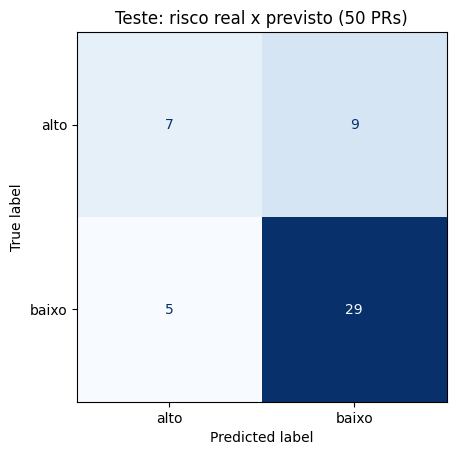

Condições aprendidas:
|--- linhas_alteradas <= 311.50
|   |--- inclui_testes <= 0.50
|   |   |--- weights: [14.00, 42.00] class: baixo
|   |--- inclui_testes >  0.50
|   |   |--- weights: [5.00, 55.00] class: baixo
|--- linhas_alteradas >  311.50
|   |--- arquivos_alterados <= 11.50
|   |   |--- weights: [10.00, 0.00] class: alto
|   |--- arquivos_alterados >  11.50
|   |   |--- weights: [19.00, 5.00] class: alto



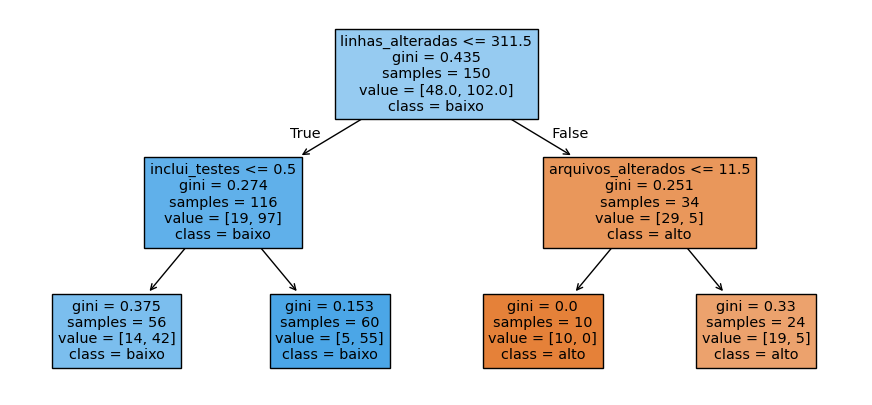

In [6]:
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)

print(f"Acurácia no treino: {accuracy_score(y_treino, modelo.predict(X_treino)):.1%}")
print(f"Acurácia no teste:  {accuracy_score(y_teste, previsoes):.1%}")
print(f"PRs de risco alto que o modelo pegou no teste: "
      f"{recall_score(y_teste, previsoes, pos_label='alto'):.1%}\n")

classes = ["alto", "baixo"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print(pd.DataFrame(matriz, index=["real alto", "real baixo"],
                   columns=["previsto alto", "previsto baixo"]))

ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title(f"Teste: risco real x previsto ({len(y_teste)} PRs)")
plt.show()

# show_weights mostra quantos PRs de cada classe caíram em cada folha, na ordem [alto, baixo]
print("Condições aprendidas:")
print(export_text(modelo, feature_names=list(X.columns), show_weights=True))

plt.figure(figsize=(11, 5))
plot_tree(modelo, feature_names=list(X.columns),
          class_names=list(modelo.classes_), filled=True)
plt.show()

A árvore leu os dados assim: até 311,5 linhas o risco é baixo, acima disso é alto. O corte ficou perto dos 300 que eu coloquei no gerador. Ela também separou os PRs pequenos por teste (14 de 56 sem teste deram problema, contra 5 de 60 com teste) e os grandes por quantidade de arquivos, mas as duas folhas de cada lado ficaram com a mesma classe. Essas divisões deixam as folhas mais puras (o Gini diminui) sem mudar nenhuma previsão.

No teste a acurácia foi 72%, abaixo dos 84% no treino e dos 83,3% da validação cruzada. Com 50 PRs no teste cada PR vale 2 pontos percentuais, então a diferença para a validação cruzada são uns 5 PRs, e parte disso é variação de amostra.

O número que mais me incomodou foi o recall: dos 16 PRs de risco alto no teste, o modelo pegou 7 (43,8%). Os 9 que passaram são todos PRs pequenos, entre 13 e 297 linhas, e 7 deles não tinham teste. A árvore não tem como pegar esses casos, porque na folha deles a maioria dos PRs não deu problema. Os 5 falsos positivos são PRs entre 433 e 580 linhas que não deram problema, e esse é o erro que eu prefiro cometer.

A regra R5 compensa parte disso. Ela pede teste para PR de risco baixo sem teste, e com isso 7 dos 9 PRs que o modelo deixou passar recebem pelo menos esse pedido (considerando `area_critica = False`). Em troca, 7 PRs que não deram problema também recebem o pedido, o que custa pouco.

## 7. Base de conhecimento e motor de inferência

| Regra | SE | ENTÃO | De onde veio |
|:--|:--|:--|:--|
| D1 | `linhas_alteradas` > 400 | `pr_grande` | Recomendação da SmartBear de revisar no máximo 400 linhas de código por vez, tirada de um estudo feito com a equipe da Cisco. |
| R0 | `area_critica` desconhecida | perguntar ao autor antes de recomendar | Aula 12: não saber se há papel é diferente de saber que não há papel. |
| R1 | risco alto E área crítica | dois revisores e teste em homologação antes do merge | Escolha minha, juntando duas configurações do GitHub: code owners e o número mínimo de aprovações na proteção de branch. |
| R2 | risco alto E `pr_grande` | pedir para o autor dividir o PR | Mesma origem da D1: PR grande demais não é revisado direito. |
| R3 | risco alto | revisão com checklist | Escolha minha, para o risco alto que não cai na R1 nem na R2. |
| R4 | risco baixo E área crítica | uma revisão, de quem cuida daquela parte do código | Arquivo `CODEOWNERS` do GitHub, que define quem é responsável por cada parte do repositório. |
| R5 | risco baixo E sem teste | pedir pelo menos um teste antes de aprovar | Veio dos dados: no treino, PR de até 311 linhas sem teste deu problema em 25% dos casos, contra 8% com teste. A árvore deixa os dois como baixo, então a regra cobre essa diferença. |
| R6 | risco baixo | revisão normal, merge com uma aprovação | Caso padrão. |

A ordem da lista é a prioridade. O motor aplica a primeira regra cujas condições batem com os fatos, então coloquei as mais específicas antes das gerais (R1 antes da R3, R4 antes da R6), que é um dos critérios de desempate da aula 12. A D1 roda antes de todas e acrescenta o fato `pr_grande`, de modo que a R2 usa um fato deduzido pelo próprio sistema: é encadeamento para frente em dois passos, D1 e depois R2.

O limite de 300 linhas no gerador e o de 400 na D1 são coisas diferentes. O primeiro é a minha suposição sobre quando o risco sobe. O segundo é o tamanho a partir do qual a revisão perde qualidade, segundo a SmartBear.

In [7]:
# Limite da regra D1 (recomendação da SmartBear). Não vem do modelo.
LIMITE_LINHAS = 400

# Base de conhecimento. A ordem importa: vale a primeira regra cujas condições batem.
regras = [
    {"id": "R0", "se": {"area_critica": None},
     "entao": "Perguntar ao autor se o PR mexe em autenticação, pagamento ou banco antes de recomendar."},
    {"id": "R1", "se": {"risco": "alto", "area_critica": True},
     "entao": "Pedir dois revisores e testar em homologação antes do merge."},
    {"id": "R2", "se": {"risco": "alto", "pr_grande": True},
     "entao": "Pedir para o autor dividir o PR em partes menores antes da revisão."},
    {"id": "R3", "se": {"risco": "alto"},
     "entao": "Revisar com checklist: casos de erro, testes e como desfazer se der problema."},
    {"id": "R4", "se": {"risco": "baixo", "area_critica": True},
     "entao": "Uma revisão, feita por quem cuida daquela parte do código (code owner)."},
    {"id": "R5", "se": {"risco": "baixo", "inclui_testes": 0},
     "entao": "Pedir pelo menos um teste antes de aprovar."},
    {"id": "R6", "se": {"risco": "baixo"},
     "entao": "Revisão normal. Pode fazer merge com uma aprovação."},
]


def derivar_fatos(fatos):
    """Encadeamento para frente: acrescenta os fatos que saem de outros fatos."""
    novos = dict(fatos)
    rastro = []
    # D1: SE linhas_alteradas > LIMITE_LINHAS ENTÃO pr_grande
    novos["pr_grande"] = novos["linhas_alteradas"] > LIMITE_LINHAS
    if novos["pr_grande"]:
        rastro.append(f"D1: {novos['linhas_alteradas']} linhas > {LIMITE_LINHAS}, então pr_grande")
    return novos, rastro


def aplicar_regras(fatos):
    """Motor de inferência: procura a primeira regra compatível e guarda o rastro."""
    fatos, rastro = derivar_fatos(fatos)
    for regra in regras:
        if all(fatos.get(chave) == valor for chave, valor in regra["se"].items()):
            condicoes = " E ".join(f"{chave} = {valor}" for chave, valor in regra["se"].items())
            rastro.append(f"{regra['id']}: SE {condicoes}")
            return {"regra": regra["id"], "recomendacao": regra["entao"], "rastro": rastro}
    raise ValueError(f"Nenhuma regra cobre estes fatos: {fatos}")

## 8. Integrar o modelo ao sistema especialista

A função `triar_pr` valida a entrada, pede o risco para a árvore e passa tudo para o motor. Além da regra, ela devolve `alto_na_folha`: a proporção de PRs de risco alto, no treino, dentro da folha onde o PR caiu. Não chamo isso de probabilidade porque a árvore não foi calibrada para isso (aula 12: um valor de confiança só é probabilidade quando o modelo o define assim). É só a informação de quantos PRs parecidos deram problema.

In [8]:
def triar_pr(linhas, arquivos, inclui_testes, area_critica):
    """A árvore prevê o risco e as regras decidem a recomendação.

    area_critica pode ser True, False ou None (quando ninguém sabe ainda).
    """
    if not isinstance(linhas, int) or linhas < 1:
        raise ValueError("linhas deve ser um inteiro maior que zero.")
    if not isinstance(arquivos, int) or not 1 <= arquivos <= linhas:
        raise ValueError("arquivos deve ser um inteiro entre 1 e o número de linhas.")
    if inclui_testes not in (0, 1):
        raise ValueError("inclui_testes deve ser 0 ou 1.")
    if area_critica is not None and not isinstance(area_critica, bool):
        raise ValueError("area_critica deve ser True, False ou None.")

    novo_pr = pd.DataFrame([{"linhas_alteradas": linhas,
                             "arquivos_alterados": arquivos,
                             "inclui_testes": inclui_testes}])

    # 1. Classificação: a árvore prevê o risco.
    risco = modelo.predict(novo_pr)[0]
    alto_na_folha = modelo.predict_proba(novo_pr)[0][list(modelo.classes_).index("alto")]

    # 2. Inferência: o risco previsto entra como fato junto com o que o time informou.
    fatos = {"linhas_alteradas": linhas, "arquivos_alterados": arquivos,
             "inclui_testes": inclui_testes, "area_critica": area_critica,
             "risco": risco}
    resultado = aplicar_regras(fatos)

    fora = any(not X_treino[c].min() <= novo_pr[c].iloc[0] <= X_treino[c].max()
               for c in X.columns)
    return {
        "risco_previsto": risco,
        "alto_na_folha": f"{alto_na_folha:.0%}",
        **resultado,
        "aviso": ("Valores fora do que apareceu no treino; a previsão é menos confiável."
                  if fora else "Sugestão para quem revisa. A decisão continua sendo do revisor."),
    }


def mostrar(titulo, resultado):
    print(titulo)
    for campo, valor in resultado.items():
        if campo == "rastro":
            print("rastro:")
            for passo in valor:
                print("   ", passo)
        else:
            print(f"{campo}: {valor}")
    print()

## 9. Três PRs novos

Nenhum dos três está no dataset. Inventei um título para cada um só para ficar mais fácil de imaginar.

In [9]:
casos = [
    ("PR-A: corrige o texto de uma mensagem de erro", 18, 2, 1, False),
    ("PR-B: refatora o módulo de relatórios", 950, 23, 0, False),
    ("PR-C: troca a biblioteca de hash de senha", 340, 6, 1, True),
]

for titulo, linhas, arquivos, testes, critica in casos:
    mostrar(f"{titulo}\n({linhas} linhas, {arquivos} arquivos, "
            f"inclui_testes={testes}, area_critica={critica})",
            triar_pr(linhas, arquivos, testes, critica))

PR-A: corrige o texto de uma mensagem de erro
(18 linhas, 2 arquivos, inclui_testes=1, area_critica=False)
risco_previsto: baixo
alto_na_folha: 8%
regra: R6
recomendacao: Revisão normal. Pode fazer merge com uma aprovação.
rastro:
    R6: SE risco = baixo
aviso: Sugestão para quem revisa. A decisão continua sendo do revisor.

PR-B: refatora o módulo de relatórios
(950 linhas, 23 arquivos, inclui_testes=0, area_critica=False)
risco_previsto: alto
alto_na_folha: 79%
regra: R2
recomendacao: Pedir para o autor dividir o PR em partes menores antes da revisão.
rastro:
    D1: 950 linhas > 400, então pr_grande
    R2: SE risco = alto E pr_grande = True
aviso: Sugestão para quem revisa. A decisão continua sendo do revisor.

PR-C: troca a biblioteca de hash de senha
(340 linhas, 6 arquivos, inclui_testes=1, area_critica=True)
risco_previsto: alto
alto_na_folha: 100%
regra: R1
recomendacao: Pedir dois revisores e testar em homologação antes do merge.
rastro:
    R1: SE risco = alto E area_critic

PR-A: 18 linhas em 2 arquivos, com teste, fora de área crítica. Caiu na folha mais tranquila da árvore (8% de risco alto no treino). Como o risco é baixo e ele tem teste, nenhuma regra mais específica bate e vale a R6, revisão normal.

PR-B: 950 linhas em 23 arquivos, sem teste. A árvore prevê alto (79% de alto na folha). Antes das regras de recomendação, a D1 deduz `pr_grande` porque passou de 400 linhas, e a R2 usa esse fato para pedir que o PR seja dividido.

PR-C: 340 linhas em 6 arquivos, com teste, mexendo em senha. Passou de 311 linhas, então a árvore prevê alto mesmo com teste. Como é área crítica, a R1 vem antes da R3 e recomenda dois revisores e teste em homologação. O 100% da folha precisa ser lido com cuidado: são só 10 PRs de treino naquela folha, todos de risco alto, e 10 exemplos não bastam para dizer que todo PR assim dá problema.

## 10. Mudando só a área crítica

Mesmos números de PR, trocando só o fato `area_critica`. Usei o PR-C e um PR pequeno sem teste.

In [10]:
comparacao = []
for linhas, arquivos, testes in [(340, 6, 1), (150, 4, 0)]:
    for critica in (True, False, None):
        r = triar_pr(linhas, arquivos, testes, critica)
        comparacao.append({"linhas": linhas, "teste": testes, "area_critica": critica,
                           "risco_previsto": r["risco_previsto"], "regra": r["regra"],
                           "recomendacao": r["recomendacao"]})

pd.set_option("display.max_colwidth", 90)
print(pd.DataFrame(comparacao).to_string(index=False))

 linhas  teste area_critica risco_previsto regra                                                                             recomendacao
    340      1         True           alto    R1                             Pedir dois revisores e testar em homologação antes do merge.
    340      1        False           alto    R3            Revisar com checklist: casos de erro, testes e como desfazer se der problema.
    340      1         None           alto    R0 Perguntar ao autor se o PR mexe em autenticação, pagamento ou banco antes de recomendar.
    150      0         True          baixo    R4                  Uma revisão, feita por quem cuida daquela parte do código (code owner).
    150      0        False          baixo    R5                                              Pedir pelo menos um teste antes de aprovar.
    150      0         None          baixo    R0 Perguntar ao autor se o PR mexe em autenticação, pagamento ou banco antes de recomendar.


Nos dois PRs a previsão do modelo ficou igual nas três linhas, porque `area_critica` não é atributo da árvore. Só a regra escolhida pelo motor mudou. No PR de 340 linhas o risco continua alto e a recomendação passa de dois revisores (R1) para checklist (R3) e depois para a pergunta ao autor (R0). No PR de 150 linhas sem teste o risco continua baixo, e a recomendação passa de code owner (R4) para pedir teste (R5).

Percebi um problema nessa tabela. Quando é área crítica, a R4 ganha da R5, e o PR pequeno sem teste deixa de receber o pedido de teste. Como o motor para na primeira regra que bate, as recomendações não se somam. Para usar de verdade, eu faria o motor juntar todas as recomendações que se aplicam, ou escreveria uma regra para o caso "baixo, área crítica e sem teste".

## 11. Testes das regras

Testes do motor sem passar pelo modelo (o risco é informado direto), seguindo os três tipos da aula 12: positivo, negativo e informação ausente. No fim, todas as combinações de fatos passam pelo motor para conferir que nenhuma fica sem regra e que nenhuma regra é inalcançável.

In [11]:
base = {"linhas_alteradas": 200, "arquivos_alterados": 5, "inclui_testes": 1}

# Positivo: todas as condições da R1 estão presentes.
assert aplicar_regras({**base, "risco": "alto", "area_critica": True})["regra"] == "R1"
# Negativo: falta uma condição da R1 (não é área crítica), então ela não pode disparar.
assert aplicar_regras({**base, "risco": "alto", "area_critica": False})["regra"] != "R1"
# Informação ausente: não saber é diferente de "não".
assert aplicar_regras({**base, "risco": "alto", "area_critica": None})["regra"] == "R0"
# Encadeamento: D1 deduz pr_grande e a R2 usa esse fato.
r = aplicar_regras({**base, "linhas_alteradas": 900, "risco": "alto", "area_critica": False})
assert r["regra"] == "R2" and r["rastro"][0].startswith("D1")

usadas = set()
combinacoes = 0
for risco in ("alto", "baixo"):
    for critica in (True, False, None):
        for testes in (0, 1):
            for linhas in (100, 900):
                fatos = {"linhas_alteradas": linhas, "arquivos_alterados": 5,
                         "inclui_testes": testes, "risco": risco, "area_critica": critica}
                usadas.add(aplicar_regras(fatos)["regra"])
                combinacoes += 1

assert usadas == {regra["id"] for regra in regras}, usadas
print(f"Testes passaram. {combinacoes} combinações de fatos, todas com regra; "
      f"as {len(usadas)} regras foram usadas pelo menos uma vez.")

Testes passaram. 24 combinações de fatos, todas com regra; as 7 regras foram usadas pelo menos uma vez.


## 12. Análise dos resultados

### Qual parte do programa aprende com os dados?

A árvore de decisão da seção 6. As condições dela (`linhas_alteradas <= 311.5`, `inclui_testes <= 0.5` e `arquivos_alterados <= 11.5`) saíram do `fit` com os 150 PRs de treino. Com outro dataset, as condições seriam outras.

### Qual parte aplica regras humanas?

A base de conhecimento e o motor da seção 7. Fui eu que escrevi cada regra, e a tabela da seção 7 mostra de onde veio cada uma. A R5 nasceu de um número que vi nos dados, mas quem transformou esse número em recomendação fui eu. O modelo só prevê o risco e não recomenda nada.

### Por que a área crítica não aparece entre os atributos do modelo?

O motivo direto é que ela não está no dataset. Mesmo que estivesse, acho que ficaria melhor fora. Se um PR mexe em pagamento, o time quer cuidado extra por política, e isso se escreve como regra. E num histórico real os PRs de área crítica provavelmente já são revisados com mais cuidado e por isso podem aparecer com menos problemas. Um modelo treinado nesse histórico poderia aprender que área crítica tem risco menor, o contrário do que o time quer.

### O que acontece ao mudar só esse fato?

A previsão fica igual e só a regra muda (seção 10). O que a árvore aprendeu não depende do que o time informa na consulta, e as duas partes do sistema continuam separadas.

### Um resultado de 100% em quatro casos é suficiente para uso real?

Não. No notebook da professora, 100% em 4 casos quer dizer 4 acertos, e um único erro já derrubaria para 75%. Aqui o teste tem 50 PRs e deu 72%, e mesmo assim não serve para uso real, porque os dados são simulados. O mesmo vale para o 100% da folha do PR-C, que tem só 10 exemplos.

### Erros

Os erros que importam são os 9 falsos negativos da seção 6, todos PRs pequenos e a maioria sem teste. A árvore com profundidade 2 não consegue separar esses casos, porque mesmo sem teste só 1 em cada 4 PRs pequenos deu problema no treino. A R5 cobre parte deles pedindo teste, mas 2 PRs de risco alto ainda saem com "revisão normal". Para pegar mais PRs de risco eu poderia treinar com `class_weight="balanced"`, que dá mais peso à classe menor, ou escolher a profundidade pelo recall da classe `alto` em vez da acurácia. Não fiz isso porque teria que decidir quanto vale cada tipo de erro, e sem dado real eu estaria só chutando.

### Limitações

O maior problema é que os dados são meus. A árvore achou o corte de 300 linhas porque fui eu que coloquei esse corte no gerador, então o modelo reaprendeu a minha suposição. Com PRs reais não há garantia de que o padrão exista, nem de que o corte seja esse.

Três atributos é pouco. O risco real de um PR depende também de quão complexo é o código alterado e de quanto o autor conhece aquela parte do sistema, e nada disso está aqui.

O rótulo também é uma simplificação. Um bug que aparece no 15º dia conta como risco baixo, e um hotfix pode não ter relação com o PR que veio antes dele.

Na seção 10 apareceu mais uma: o motor para na primeira regra e não soma recomendações.

### Representatividade

O dataset tem poucos PRs nos extremos. Só 6 dos 200 passam de 800 linhas e só 3 passam de 1000, então o efeito de "mais de 800 linhas" que coloquei no gerador quase não aparece para a árvore. O teste tem 16 PRs de risco alto, pouco para medir recall com segurança, já que cada PR muda o resultado em mais de 6 pontos. Os dados também imitam um tipo só de projeto. Um time que usa feature flags ou faz deploy várias vezes por dia teria outro padrão de problema depois do merge.

### Cuidados com dados pessoais

Deixei de fora quem é o autor do PR. Dados reais do GitHub vêm com o nome de usuário, e com isso o modelo poderia virar uma ferramenta para avaliar pessoas ("os PRs dele sempre dão problema"), o que foge do objetivo da triagem. Com dados reais eu guardaria só os números do PR, sem o autor, e deixaria claro para o time para que os dados servem, como pede o princípio da finalidade da LGPD (art. 6º, I). A saída do sistema também avisa que a recomendação é uma sugestão e que a decisão continua sendo de quem revisa.

### Como seria com dados reais

A API do GitHub dá, para cada PR, as linhas adicionadas e removidas, a quantidade de arquivos e a lista de arquivos, e pela lista dá para ver se algum está numa pasta de testes. O rótulo daria para montar procurando commits de revert ou PRs de hotfix que citam o PR original nos 14 dias seguintes ao merge. Essa segunda parte é a mais difícil, porque depende de o time escrever as mensagens de commit de um jeito que permita achar essa ligação.

## Referências

BELCIC, Ivan; STRYKER, Cole. O que é aprendizado supervisionado? IBM Think, 2025. Disponível em: https://www.ibm.com/br-pt/think/topics/supervised-learning

GITHUB. About code owners. GitHub Docs. Disponível em: https://docs.github.com/en/repositories/managing-your-repositorys-settings-and-features/customizing-your-repository/about-code-owners

SCIKIT-LEARN. DecisionTreeClassifier. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

SCIKIT-LEARN. Cross-validation: evaluating estimator performance. Disponível em: https://scikit-learn.org/stable/modules/cross_validation.html

SCIKIT-LEARN. train_test_split. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

SMARTBEAR. Best Practices for Code Review. Disponível em: https://smartbear.com/learn/code-review/best-practices-for-peer-code-review/

STRYKER, Cole; LEE, Fangfang; BERGMANN, Dave; SCAPICCHIO, Mark. Guia do aprendizado de máquina de 2026. IBM Think, 2025. Disponível em: https://www.ibm.com/br-pt/think/machine-learning

VALÉRIA, Kadidja. Aula 12: Sistemas especialistas. Material da disciplina, 2026.

VALÉRIA, Kadidja. Aula 13: Aprendizado de máquina, introdução. Notebook `Aprendizado_Maquina_Introducao.ipynb`, 2026.